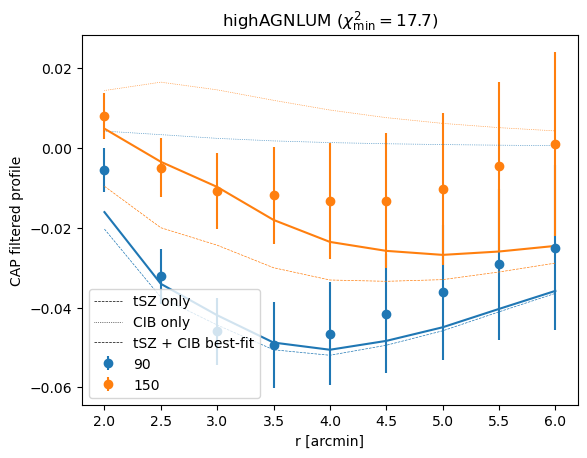

[0.03184382 0.15055269 2.15018225 0.69241541 1.38024388]


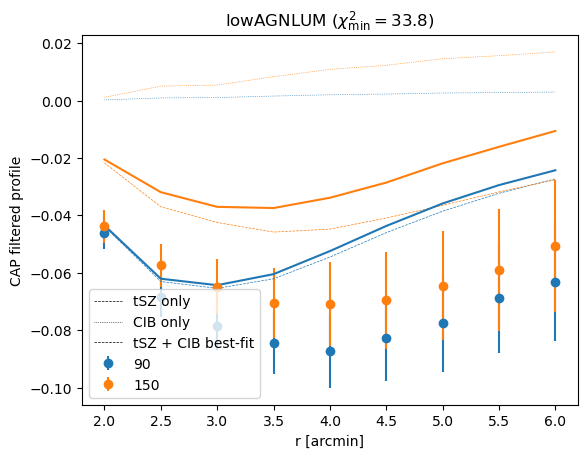

[0.00808206 0.2236951  5.87851167 1.97753607 1.12595878]


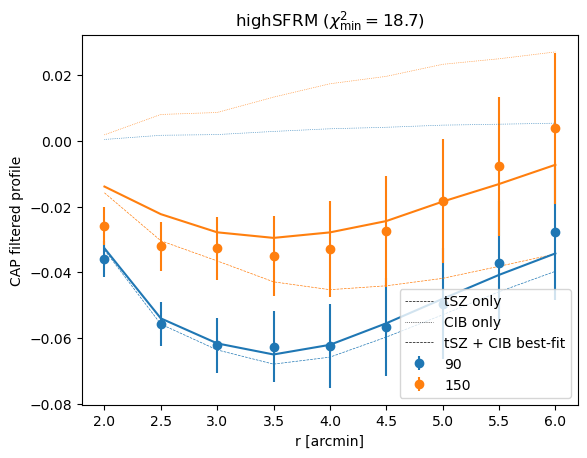

[0.01459478 0.20727166 5.19647299 1.9769372  1.28047766]


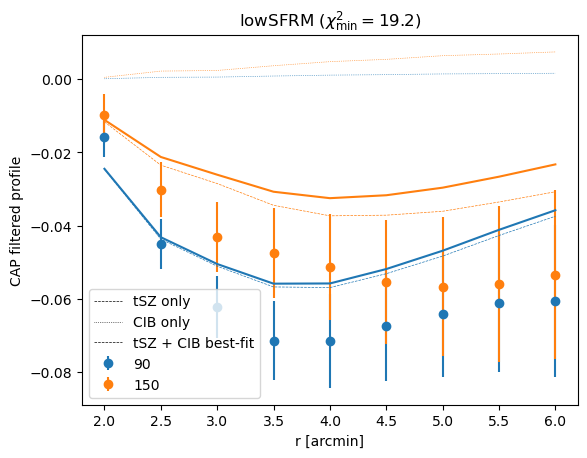

[4.38823267e-03 1.69411868e-01 4.74337172e+00 1.97115993e+00
 1.33875772e+00]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from theory_90v150 import rbin,compute_binned_profiles

ddir = 'abbys_data'
odir = 'chains'
fdir = 'figures'

for kind in ['highAGNLUM','lowAGNLUM','highSFRM','lowSFRM']:
    # load data and chain
    data  = np.loadtxt(f'{ddir}/{kind}_d_vector.txt')
    cov   = np.loadtxt(f'{ddir}/{kind}_fixed_covariance.txt')
    chain = np.loadtxt(f'{odir}/chains_{kind}.txt')
    # find the best-fit
    bfidx = np.argmin(chain[:,0])
    best_fit_chi2 = 2*chain[bfidx,0]
    best_fit_params = chain[bfidx,1:]
    # make plot
    # data
    error90 = np.diag(cov)[:9]**0.5
    error150 = np.diag(cov)[9:]**0.5
    r = 1/np.pi/rbin**2
    plt.errorbar(rbin,r*data[:9],yerr=r*error90,label=r'90',c='C0',ls='',marker='o')
    plt.errorbar(rbin,r*data[9:],yerr=r*error150,label=r'150',c='C1',ls='',marker='o')
    # model
    a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz = best_fit_params
    plt.plot(rbin,r*compute_binned_profiles(0*a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz)[:9],c='C0',ls='--',lw=0.5)
    plt.plot(rbin,r*compute_binned_profiles(0*a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz)[9:],c='C1',ls='--',lw=0.5)
    plt.plot(rbin,r*compute_binned_profiles(a_cib,0*a_tsz,r_cib,sigma_cib,sigma_tsz)[:9],c='C0',ls='dotted',lw=0.5)
    plt.plot(rbin,r*compute_binned_profiles(a_cib,0*a_tsz,r_cib,sigma_cib,sigma_tsz)[9:],c='C1',ls='dotted',lw=0.5)
    plt.plot(rbin,r*compute_binned_profiles(a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz)[:9],c='C0')
    plt.plot(rbin,r*compute_binned_profiles(a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz)[9:],c='C1')
    plt.plot([],[],c='k',lw=0.5,ls='--',label='tSZ only')
    plt.plot([],[],c='k',lw=0.5,ls='dotted',label='CIB only')
    plt.plot([],[],c='k',lw=0.5,ls='--',label='tSZ + CIB best-fit')
    plt.legend()
    plt.xlabel(r'r [arcmin]')
    plt.ylabel(r'CAP filtered profile')
    plt.title(kind+' '+r'$(\chi^2_\mathrm{min}=$'+str(np.round(best_fit_chi2,1))+')')
    plt.savefig(f'{fdir}/{kind}_data_and_best_fits.png')
    plt.show()
    print(best_fit_params)

In [2]:
from astropy.table import Table

cat_agn = Table.read('abbys_data/11.10.prebox_bgslrg_agnlum_uw_overlap_cmsk_boxes_evenSplit.fits')

/Users/nsailer/opt/anaconda3/lib/python3.13/site-packages/astropy/units/core.py:2145: UnitsWarning: 'log(solMass)' did not parse as fits unit: 'log' is not a recognized function If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html
  warnings.warn(msg, UnitsWarning)
/Users/nsailer/opt/anaconda3/lib/python3.13/site-packages/astropy/units/core.py:2145: UnitsWarning: 'log(solMass)' did not parse as fits unit: 'log' is not a recognized function If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html
  warnings.warn(msg, UnitsWarning)
/Users/nsailer/opt/anaconda3/lib/python3.13/site-packages/astropy/units/core

In [40]:
cat_agn_low = cat_agn[np.where(cat_agn['split']=='low')]

profiles = cat_agn_low['profile_ringring2_90ghz']

In [41]:
# remove outliers
nsig_thresh = 3

mean=np.mean(profiles,axis=0)
std =np.std(profiles,axis=0)

print('original mean',mean)

new_profiles = profiles.copy()
for i in range(9):
    new_profiles = new_profiles[np.where(np.abs(new_profiles[:,i]-mean[i])<nsig_thresh*std[i])]

print('new mean',np.mean(new_profiles,axis=0))

original mean [-0.57861486 -1.34591144 -2.21898188 -3.25314349 -4.387728   -5.25343263
 -6.0905243  -6.55000456 -7.1371271 ]
new mean [-0.5056366  -1.13986214 -1.85526477 -2.64990571 -3.51501084 -4.0864981
 -4.60233781 -4.68418962 -4.86638533]


# Old stuff

Text(0.5, 1.0, 'high AGN luminosity')

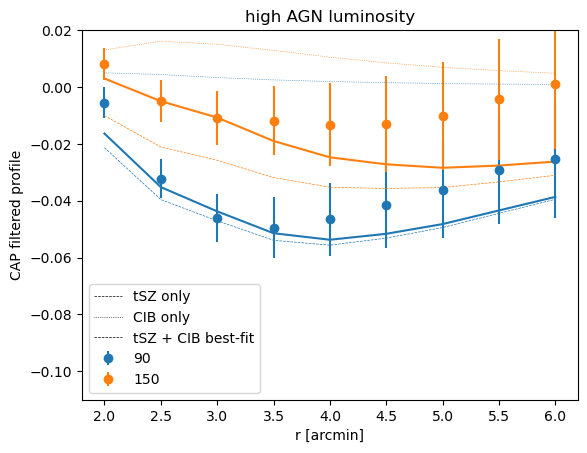

In [9]:
# make plot
# data
error90 = np.diag(cov)[:9]**0.5
error150 = np.diag(cov)[9:]**0.5
r = 1/np.pi/rbin**2
plt.errorbar(rbin,r*data[:9],yerr=r*error90,label=r'90',c='C0',ls='',marker='o')
plt.errorbar(rbin,r*data[9:],yerr=r*error150,label=r'150',c='C1',ls='',marker='o')
# model
a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz = best_fit_params

plt.plot(rbin,r*compute_binned_profiles(0*a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz)[:9],c='C0',ls='--',lw=0.5)
plt.plot(rbin,r*compute_binned_profiles(0*a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz)[9:],c='C1',ls='--',lw=0.5)

plt.plot(rbin,r*compute_binned_profiles(a_cib,0*a_tsz,r_cib,sigma_cib,sigma_tsz)[:9],c='C0',ls='dotted',lw=0.5)
plt.plot(rbin,r*compute_binned_profiles(a_cib,0*a_tsz,r_cib,sigma_cib,sigma_tsz)[9:],c='C1',ls='dotted',lw=0.5)


plt.plot(rbin,r*compute_binned_profiles(a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz)[:9],c='C0')
plt.plot(rbin,r*compute_binned_profiles(a_cib,a_tsz,r_cib,sigma_cib,sigma_tsz)[9:],c='C1')

plt.plot([],[],c='k',lw=0.5,ls='--',label='tSZ only')
plt.plot([],[],c='k',lw=0.5,ls='dotted',label='CIB only')
plt.plot([],[],c='k',lw=0.5,ls='--',label='tSZ + CIB best-fit')

plt.ylim(-0.11,0.02)

plt.legend()
plt.xlabel(r'r [arcmin]')
plt.ylabel(r'CAP filtered profile')
plt.title(r'high AGN luminosity')

In [2]:
np.min(mlogL)*2

np.float64(17.91849943246673)

Removed no burn in
Mean values:
[0.02656845 0.15833063 3.5201977  0.50747195 1.42888284]

Covariance matrix:


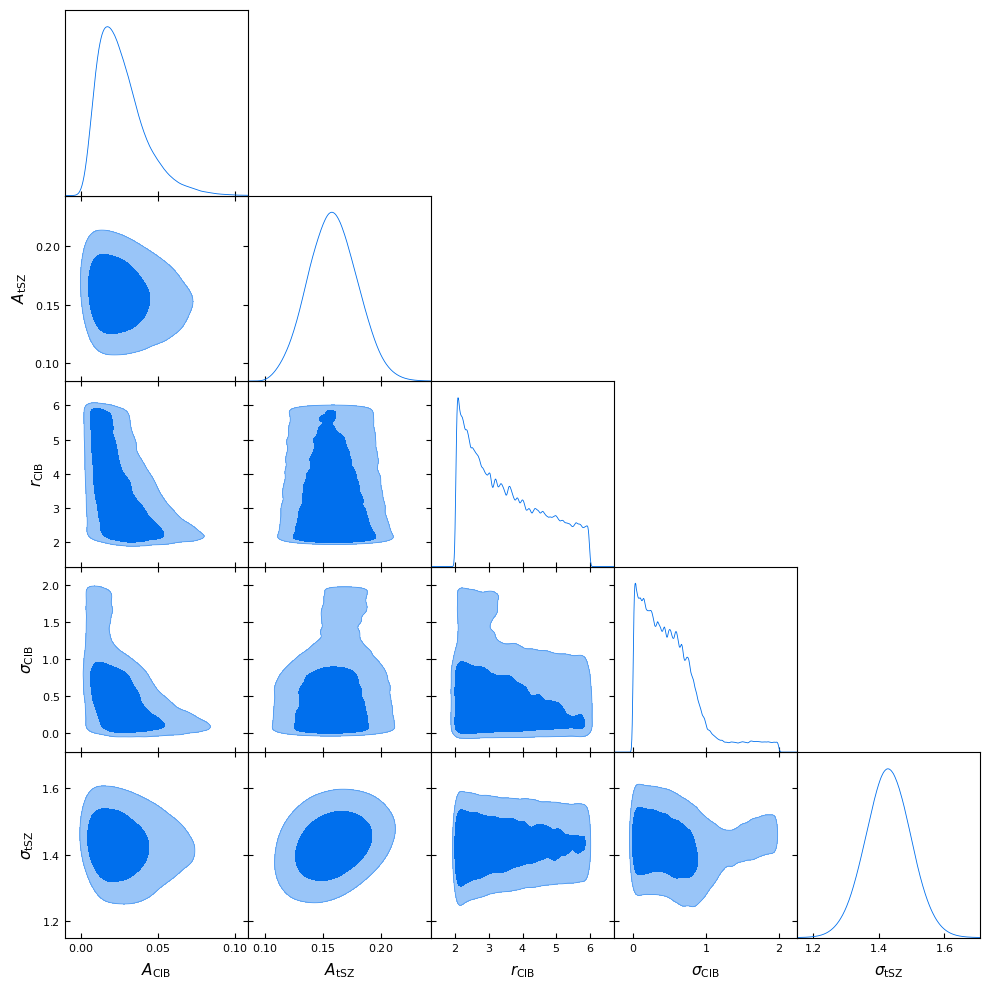

In [2]:
import numpy as np
from getdist import MCSamples, plots

# ======================================================
# 1. Load or define your data
# ======================================================
# Example placeholders — replace with your actual arrays
# params should be shape (N, n_params)
# minuslogL should be shape (N,)

# Example:
# params = np.loadtxt('params.txt')        # N x n_params
# minuslogL = np.loadtxt('minusloglike.txt')  # N

# For illustration:
# params = np.random.rand(10000, 3)
# minuslogL = np.random.normal(100, 5, size=10000)

# ======================================================
# 2. Convert -logL to weights
# ======================================================
logL = -mlogL
logL -= np.max(logL)        # stabilize numerically
weights = np.exp(logL)
weights /= np.sum(weights)  # normalize (optional but cleaner)

# ======================================================
# 3. Define parameter names and labels
# ======================================================
names = ['a_cib','a_tsz','r_cib','sigma_cib','sigma_tsz'] 
labels = [r'A_\mathrm{CIB}',r'A_\mathrm{tSZ}',r'r_\mathrm{CIB}',r'\sigma_\mathrm{CIB}',r'\sigma_\mathrm{tSZ}']

# ======================================================
# 4. Create GetDist MCSamples object
# ======================================================
samples = MCSamples(samples=params.T,
                    weights=weights,
                    loglikes=logL,
                    names=names,
                    labels=labels)

# ======================================================
# 5. (Optional) Save chain in GetDist-compatible format
# ======================================================
#samples.saveAsText('mychain')  # writes mychain.txt and mychain.paramnames

# ======================================================
# 6. Make a corner (triangle) plot
# ======================================================
g = plots.get_subplot_plotter()
g.triangle_plot([samples], filled=True)

# ======================================================
# 7. Print some stats
# ======================================================
print("Mean values:")
print(samples.getMeans())

print("\nCovariance matrix:")
print(samples.getCovMat())
